In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

(7043, 21)


In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())  # should be 0



0


In [3]:
df = df.drop(columns=["customerID"])
print(df.duplicated().sum())

22


In [4]:
no_internet_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                    "TechSupport", "StreamingTV", "StreamingMovies"]
for c in no_internet_cols:
    df[c] = df[c].replace("No internet service", "No")

df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

In [5]:
cat_cols = df.select_dtypes(include="object").columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print(df_encoded.shape)
df_encoded.head()

(7043, 24)


C:\Users\ometh\AppData\Local\Temp\ipykernel_33648\2071578109.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,1,29.85,29.85,0,1,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,1,1
3,0,45,42.30,1840.75,1,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,1,...,0,0,0,0,0,1,0,1,0,1


In [6]:
df_encoded = df_encoded.rename(columns={"Churn_Yes": "Churn"})
df_encoded["Churn"].value_counts()


Churn
0    5174
1    1869
Name: count, dtype: int64

In [7]:
cat_cols = df.select_dtypes(exclude="number").columns

In [8]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())  # both ~0.265

(5634, 23) (1409, 23)
0.2653532126375577 0.2654364797728886


In [9]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

knn = KNeighborsClassifier()
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
rf = RandomForestClassifier(class_weight="balanced", random_state=42)

knn.fit(X_train_scaled, y_train)
lr.fit(X_train_scaled, y_train)
rf.fit(X_train, y_train)

models = {
    "KNN": (knn, X_test_scaled),
    "Logistic Regression": (lr, X_test_scaled),
    "Random Forest": (rf, X_test),
}
for name, (model, X_t) in models.items():
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)[:, 1]
    print(f"=== {name} ===")
    print(classification_report(y_test, pred))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3), "\n")

=== KNN ===
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1035
           1       0.55      0.55      0.55       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.76      0.76      0.76      1409

ROC-AUC: 0.792 

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842 

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.57      0.64      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.7

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for name, (model, X_t) in models.items():
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

baseline_df = pd.DataFrame(rows).round(3)
baseline_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,0.763,0.554,0.551,0.552,0.792
1,Logistic Regression,0.740,0.507,0.786,0.616,0.842
2,Random Forest,0.774,0.566,0.639,0.601,0.826


In [13]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    "KNN": (KNeighborsClassifier(),
            {"n_neighbors": [3, 5, 7, 9, 11, 15, 21],
             "weights": ["uniform", "distance"],
             "metric": ["euclidean", "manhattan"]},
            X_train_scaled),
    "Logistic Regression": (LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=1000, random_state=42),
            {"C": [0.01, 0.1, 1, 10, 100],
             "penalty": ["l1", "l2"]},
            X_train_scaled),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=42),
            {"n_estimators": [100, 200, 300],
             "max_depth": [5, 10, 20, None],
             "min_samples_split": [2, 5, 10]},
            X_train),
}

best_models = {}
for name, (estimator, grid, X_tr) in param_grids.items():
    search = GridSearchCV(estimator, grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_tr, y_train)
    best_models[name] = search.best_estimator_
    print(f"=== {name} ===")
    print("Best params:", search.best_params_)
    print("Best CV F1:", round(search.best_score_, 3), "\n")

=== KNN ===
Best params: {'metric': 'euclidean', 'n_neighbors': 21, 'weights': 'uniform'}
Best CV F1: 0.596 



c:\Users\ometh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


=== Logistic Regression ===
Best params: {'C': 0.1, 'penalty': 'l2'}
Best CV F1: 0.632 

=== Random Forest ===
Best params: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 300}
Best CV F1: 0.637 



In [14]:
knn_grid = {
    "n_neighbors": [15, 21, 27, 33, 41, 51],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"],
}
knn_search = GridSearchCV(KNeighborsClassifier(), knn_grid, scoring="f1", cv=cv, n_jobs=-1)
knn_search.fit(X_train_scaled, y_train)

print("Best params:", knn_search.best_params_)
print("Best CV F1:", round(knn_search.best_score_, 3))

best_models["KNN"] = knn_search.best_estimator_

Best params: {'metric': 'manhattan', 'n_neighbors': 41, 'weights': 'uniform'}
Best CV F1: 0.606


In [15]:
tuned_sets = {
    "KNN": X_test_scaled,
    "Logistic Regression": X_test_scaled,
    "Random Forest": X_test,
}

rows = []
for name, X_t in tuned_sets.items():
    model = best_models[name]
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)[:, 1]
    rows.append({
        "Model": name + " (tuned)",
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

tuned_df = pd.DataFrame(rows).round(3)
comparison = pd.concat([baseline_df, tuned_df], ignore_index=True)
comparison


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,0.763,0.554,0.551,0.552,0.792
1,Logistic Regression,0.740,0.507,0.786,0.616,0.842
2,Random Forest,0.774,0.566,0.639,0.601,0.826
3,KNN (tuned),0.790,0.609,0.583,0.596,0.831
4,Logistic Regression (tuned),0.744,0.511,0.783,0.619,0.841
5,Random Forest (tuned),0.757,0.528,0.783,0.631,0.844


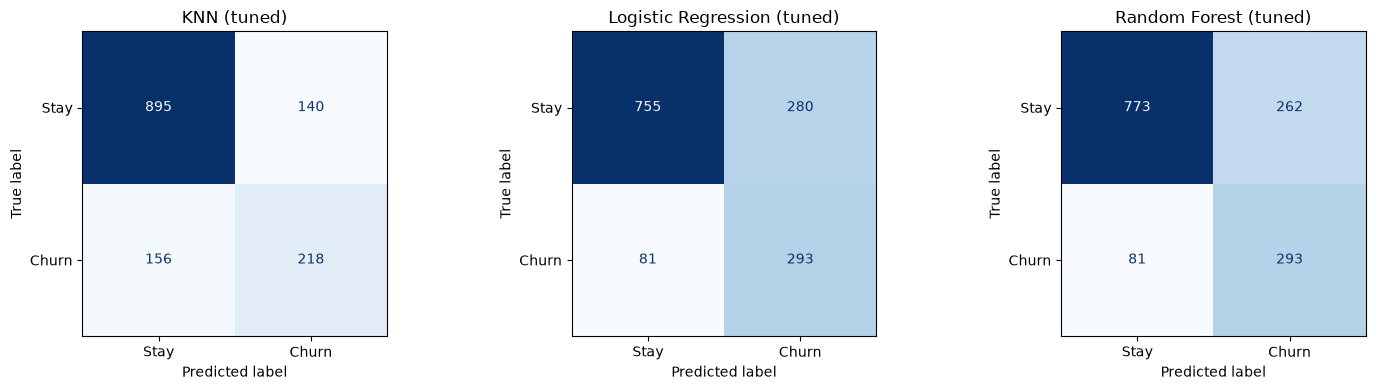

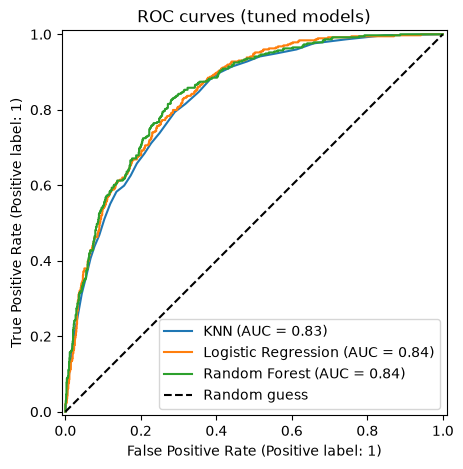

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, X_t) in zip(axes, tuned_sets.items()):
    ConfusionMatrixDisplay.from_estimator(
        best_models[name], X_t, y_test, ax=ax,
        display_labels=["Stay", "Churn"], cmap="Blues", colorbar=False
    )
    ax.set_title(name + " (tuned)")
plt.tight_layout()
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
for name, X_t in tuned_sets.items():
    RocCurveDisplay.from_estimator(best_models[name], X_t, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves (tuned models)")
ax.legend()
plt.show()